In [ ]:
# Customer churn prediction model

In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
blastchar_telco_customer_churn_path = kagglehub.dataset_download('blastchar/telco-customer-churn')
shrutimechlearn_churn_modelling_path = kagglehub.dataset_download('shrutimechlearn/churn-modelling')
rjmanoj_credit_card_customer_churn_prediction_path = kagglehub.dataset_download('rjmanoj/credit-card-customer-churn-prediction')

print('Data source import complete.')


Using Colab cache for faster access to the 'telco-customer-churn' dataset.


100%|██████████| 262k/262k [00:00<00:00, 67.0MB/s]

Extracting files...


Using Colab cache for faster access to the 'credit-card-customer-churn-prediction' dataset.
Data source import complete.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import flask as flsk

from pylab import rcParams
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [4]:
import os
csv_path = os.path.join(rjmanoj_credit_card_customer_churn_prediction_path, 'Churn_Modelling.csv')
df = pd.read_csv(csv_path)

In [7]:
df.shape
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['Exited'].value_counts()

,count
Exited,
0,7963
1,2037


In [11]:
df['Geography'].value_counts()

,count
Geography,
France,5014
Germany,2509
Spain,2477


In [12]:
df['Gender'].value_counts()

,count
Gender,
Male,5457
Female,4543


In [13]:
df.drop(columns=['RowNumber','CustomerId','Surname'], inplace=True)

In [15]:
df.shape

(10000, 11)

In [17]:
# One hot encoding
df = pd.get_dummies(df, columns=['Geography','Gender'], drop_first=True)


In [18]:
X = df.drop(columns=['Exited'])
y = df['Exited']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=1)

In [19]:
# Scaling features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
X_train_scaled

array([[ 0.71997988,  1.25618088,  0.68308948, ..., -0.58207179,
        -0.57324462,  0.91776859],
       [-0.75327193, -0.65952721, -1.39766776, ..., -0.58207179,
        -0.57324462, -1.08959928],
       [ 0.57574543,  0.39411224, -1.39766776, ..., -0.58207179,
         1.74445599, -1.08959928],
       ...,
       [ 0.22546179,  0.58568305,  1.37667523, ..., -0.58207179,
        -0.57324462, -1.08959928],
       [ 0.13273964,  0.01097062,  1.02988235, ..., -0.58207179,
        -0.57324462, -1.08959928],
       [ 1.16298567,  0.29832684,  0.33629661, ...,  1.71800114,
        -0.57324462,  0.91776859]])

In [23]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [41]:
# Model Creation

model = Sequential()

model.add(Dense(11, activation='relu', input_dim=11))  # Hidden layers where 3 neuron and 11 inputs
model.add(Dense(11, activation='relu'))                # Output layer where only one neuron
model.add(Dense(2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [42]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 2)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [56]:
# Model compilation where loss function and optimization defined and selected
model.compile(loss='binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

In [57]:
# Model training
history = model.fit(X_train_scaled, y_train, epochs=50, validation_split=0.15)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8689 - loss: 0.3180 - val_accuracy: 0.8658 - val_loss: 0.3149
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8700 - loss: 0.3178 - val_accuracy: 0.8587 - val_loss: 0.3169
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8700 - loss: 0.3175 - val_accuracy: 0.8587 - val_loss: 0.3209
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8709 - loss: 0.3175 - val_accuracy: 0.8587 - val_loss: 0.3171
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8706 - loss: 0.3170 - val_accuracy: 0.8604 - val_loss: 0.3177
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8698 - loss: 0.3165 - val_accuracy: 0.8596 - val_loss: 0.3208
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8707 - loss: 0.3169 - val_accuracy: 0.8613 - val_loss: 0.3219
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8709 - loss: 0.3168 - val_accuracy: 0.

In [58]:
# Where the training weights stored
model.layers[0].get_weights()

[array([[-0.25057846,  0.05635008, -0.3721606 , -0.05326248,  0.03217084,
          0.21052985, -0.10652986,  0.2443785 , -0.02863937,  0.25228623,
         -0.2512436 ],
        [ 1.0485804 ,  1.3372972 ,  0.34785125,  0.0175417 ,  0.29329753,
         -0.46493104, -0.36222702, -0.15794027,  0.5750332 , -0.20168501,
          0.00254802],
        [ 0.19453607,  0.01326903, -0.15413073, -0.11891952, -0.01186012,
         -0.14997093, -0.10788172, -0.10679158, -0.10143682, -0.14111902,
         -0.03035926],
        [ 0.1375527 ,  0.5789893 ,  0.00235048,  0.3647191 , -0.11661505,
          0.04025983,  1.3568147 ,  0.12532091,  0.76418173, -0.43637577,
          0.85781455],
        [ 0.7731379 , -0.6204272 ,  0.60846895,  0.8785516 , -1.1610626 ,
          0.08724041, -0.29371524,  0.77828836,  0.5575796 ,  0.42515147,
          0.49824098],
        [ 0.03613872,  0.23066112, -0.27061054, -0.00959513, -0.21226172,
          0.5664675 , -0.20422791, -0.4349388 ,  0.20584962, -0.3783503

In [59]:
# Testing
y_log = model.predict(X_test_scaled)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [60]:
y_pred = np.where(y_log>0.5,1,0)

In [61]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.8584

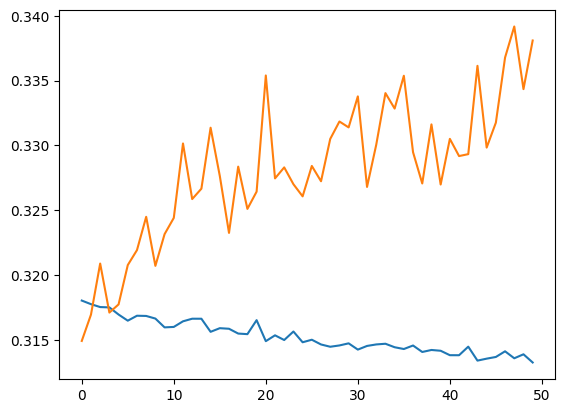

In [64]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])